Solar plant power modeling

This notebook compares the existing constant baseline, LightGBM GBM, MLP, and AE models.
Training used clean rows from the Phase-A tables; validation and test results are loaded from the saved Phase-B outputs.


In [1]:
from pathlib import Path
import json
import random

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
PHASE_A = BASE_DIR / "phase_a"
PHASE_B = BASE_DIR / "phase_b"
RESULTS_DIR = BASE_DIR / "results"
FIGURES_DIR = BASE_DIR / "figures"
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

FEATURES = [
    "irr_wm2",
    "temp_c",
    "mod_temp_c",
    "solar_elev_deg",
    "hour_sin",
    "hour_cos",
    "doy_sin",
    "doy_cos",
]
TARGET = "plant_pu"
SPLITS = ("train", "val", "test")
OFFSET_START = pd.Timestamp("2022-08-21", tz="UTC")


## Data

Phase-A tables contain the engineered weather, solar, calendar, target, and row-quality fields.
Only rows marked `clean == 1` were used for model training and the reported clean-set metrics.


In [2]:
tables = {
    split: pd.read_csv(
        PHASE_A / f"table_{split}.csv.gz",
        index_col="time_utc",
        parse_dates=True,
    )
    for split in SPLITS
}
scaler = json.loads((PHASE_A / "scaler_clean.json").read_text())
summary = json.loads((PHASE_A / "dataset_summary.json").read_text())

clean = {split: df.loc[df["clean"].eq(1)].copy() for split, df in tables.items()}
clean_counts = pd.DataFrame(
    [{"split": split, "rows": len(clean[split])} for split in SPLITS]
)
clean_counts.to_csv(RESULTS_DIR / "clean_row_counts.csv", index=False)
clean_counts


,split,rows
0,train,83135
1,val,12146
2,test,8857


## Preprocessing

Features were scaled with the clean-train median and scale values from `scaler_clean.json`.
The target was scaled with the same convention and converted back to p.u. for reporting.


In [3]:
params = scaler["params"]

def scale_x(df):
    med = pd.Series({column: params[column]["median"] for column in FEATURES})
    scale = pd.Series({column: params[column]["scale"] for column in FEATURES})
    return ((df[FEATURES] - med) / scale).to_numpy(np.float32)


def scale_y(df):
    return ((df[TARGET] - params[TARGET]["median"]) / params[TARGET]["scale"]).to_numpy(np.float32)


def unscale_y(values):
    return values * params[TARGET]["scale"] + params[TARGET]["median"]

scaled_shapes = pd.DataFrame(
    [
        {"split": split, "rows": len(clean[split]), "features": len(FEATURES)}
        for split in SPLITS
    ]
)
scaled_shapes.to_csv(RESULTS_DIR / "scaled_data_summary.csv", index=False)
scaled_shapes


,split,rows,features
0,train,83135,8
1,val,12146,8
2,test,8857,8


## Constant baseline

The baseline predicts the clean-train median target for every row.
Its metrics are retained as the reference for the learned models.


In [4]:
quality = pd.read_csv(PHASE_B / "prediction_quality.csv")

def format_metrics(frame):
    out = frame.copy()
    for column in ["MAE_std", "RMSE_std", "R2_std"]:
        out[column] = out[column].map(lambda value: "—" if pd.isna(value) else f"{value:.4f}")
    for column in ["MAE_mean", "RMSE_mean", "R2_mean"]:
        out[column] = out[column].map(lambda value: f"{value:.4f}")
    return out

constant_metrics = quality.loc[quality["model"].eq("constant")].copy()
constant_metrics.to_csv(RESULTS_DIR / "constant_metrics.csv", index=False)
format_metrics(constant_metrics)


,model,set,n_rows,n_runs,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,constant,clean train,83135,1,0.2153,—,0.2447,—,-0.0015,—
1,constant,clean val,12146,1,0.2087,—,0.2369,—,-0.0005,—
2,constant,clean val before offset,7487,1,0.2202,—,0.2477,—,-0.0024,—
3,constant,clean val inside offset,4659,1,0.1904,—,0.2184,—,-0.0006,—
4,constant,clean test,8857,1,0.2177,—,0.2471,—,-0.0216,—


### Constant baseline result

On clean test rows, the baseline has MAE 0.2177, RMSE 0.2471, and R² -0.0216.


In [5]:
print(format_metrics(constant_metrics.loc[constant_metrics["set"].eq("clean test")]).to_string(index=False))


   model        set  n_rows  n_runs MAE_mean MAE_std RMSE_mean RMSE_std R2_mean R2_std
constant clean test    8857       1   0.2177       —    0.2471        — -0.0216      —


## LightGBM GBM

The GBM used the eight scaled features, a three-value `num_leaves` search, and early stopping on clean validation rows.
The saved model and its recorded search results are used here.


In [6]:
gbm_runs = pd.DataFrame(json.loads((PHASE_B / "training_log.json").read_text())["gbm"]["runs_by_num_leaves"]).T
# Keep the original grid order and column names.
gbm_runs.index.name = "num_leaves"
gbm_runs = gbm_runs.reset_index()
gbm_runs["num_leaves"] = gbm_runs["num_leaves"].astype(int)
gbm_runs.to_csv(RESULTS_DIR / "gbm_runs.csv", index=False)

gbm = lgb.Booster(model_file=str(PHASE_B / "gbm_best.txt"))
gbm_summary = pd.DataFrame(
    [{
        "selected_num_leaves": 31,
        "best_iteration": int(gbm_runs.loc[gbm_runs["num_leaves"].eq(31), "best_iteration"].iloc[0]),
        "feature_count": gbm.num_feature(),
    }]
)
gbm_summary.to_csv(RESULTS_DIR / "gbm_summary.csv", index=False)
gbm_runs


,num_leaves,best_iteration,val_mse_scaled
0,15,120.0,0.004094
1,31,92.0,0.004073
2,63,99.0,0.004330


### GBM result

The selected model used 31 leaves. On clean test rows, it reached MAE 0.0200, RMSE 0.0259, and R² 0.9888.


In [7]:
gbm_test = quality.loc[(quality["model"].eq("gbm")) & (quality["set"].eq("clean test"))]
print(format_metrics(gbm_test).to_string(index=False))


model        set  n_rows  n_runs MAE_mean MAE_std RMSE_mean RMSE_std R2_mean R2_std
  gbm clean test    8857       1   0.0200       —    0.0259        —  0.9888      —


## MLP

The MLP used the existing `Net` architecture without the reconstruction loss: prediction loss weight 5 and reconstruction weight 0.
Results below are the three saved-seed summaries from the original run.


In [8]:
training_log = json.loads((PHASE_B / "training_log.json").read_text())
net_runs = pd.DataFrame(training_log["net_runs"])
mlp_runs = net_runs.loc[net_runs["kind"].eq("mlp")].copy()
mlp_runs["best_val_pred_mse_scaled"] = mlp_runs["best_val_pred_mse_scaled"].astype(float)
mlp_runs[["kind", "seed", "best_epoch", "epochs_run", "best_val_pred_mse_scaled"]].to_csv(
    RESULTS_DIR / "mlp_runs.csv", index=False
)
mlp_runs[["kind", "seed", "best_epoch", "epochs_run", "best_val_pred_mse_scaled"]]


,kind,seed,best_epoch,epochs_run,best_val_pred_mse_scaled
1,mlp,42,14,19,0.003692
3,mlp,43,4,9,0.004239
5,mlp,44,9,14,0.004462


### MLP result

On clean test rows, the three-seed MLP mean was MAE 0.0231 ± 0.0016, RMSE 0.0298 ± 0.0017, and R² 0.9851 ± 0.0017.


In [9]:
mlp_test = quality.loc[(quality["model"].eq("mlp")) & (quality["set"].eq("clean test"))]
print(format_metrics(mlp_test).to_string(index=False))


model        set  n_rows  n_runs MAE_mean MAE_std RMSE_mean RMSE_std R2_mean R2_std
  mlp clean test    8857       3   0.0231  0.0016    0.0298   0.0017  0.9851 0.0017


## Autoencoder model

The AE used the same encoder, decoder, and prediction head with reconstruction loss weight 1 and prediction loss weight 5.
The reported values are the three-seed summaries from the original run.


In [10]:
ae_runs = net_runs.loc[net_runs["kind"].eq("ae")].copy()
ae_runs[["kind", "seed", "best_epoch", "epochs_run", "best_val_pred_mse_scaled"]].to_csv(
    RESULTS_DIR / "ae_runs.csv", index=False
)
ae_runs[["kind", "seed", "best_epoch", "epochs_run", "best_val_pred_mse_scaled"]]


,kind,seed,best_epoch,epochs_run,best_val_pred_mse_scaled
0,ae,42,8,13,0.003955
2,ae,43,7,12,0.004465
4,ae,44,23,28,0.003550


### AE result

On clean test rows, the three-seed AE mean was MAE 0.0226 ± 0.0026, RMSE 0.0292 ± 0.0017, and R² 0.9857 ± 0.0017.


In [11]:
ae_test = quality.loc[(quality["model"].eq("ae")) & (quality["set"].eq("clean test"))]
print(format_metrics(ae_test).to_string(index=False))


model        set  n_rows  n_runs MAE_mean MAE_std RMSE_mean RMSE_std R2_mean R2_std
   ae clean test    8857       3   0.0226  0.0026    0.0292   0.0017  0.9857 0.0017


## Evaluation

The table below is the saved quality report for all existing models and evaluation sets.
The comparison chart uses the clean-test MAE and RMSE already reported in that table.


In [12]:
quality.to_csv(RESULTS_DIR / "prediction_quality.csv", index=False)
comparison = quality.loc[quality["set"].eq("clean test"), [
    "model", "n_rows", "MAE_mean", "MAE_std", "RMSE_mean", "RMSE_std", "R2_mean", "R2_std"
]].copy()
comparison.to_csv(RESULTS_DIR / "clean_test_comparison.csv", index=False)
comparison_display = comparison.copy()
for column in ["MAE_std", "RMSE_std", "R2_std"]:
    comparison_display[column] = comparison_display[column].map(
        lambda value: "—" if pd.isna(value) else f"{value:.4f}"
    )
for column in ["MAE_mean", "RMSE_mean", "R2_mean"]:
    comparison_display[column] = comparison_display[column].map(lambda value: f"{value:.4f}")
comparison_display


,model,n_rows,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
4,constant,8857,0.2177,—,0.2471,—,-0.0216,—
9,gbm,8857,0.0200,—,0.0259,—,0.9888,—
14,mlp,8857,0.0231,0.0016,0.0298,0.0017,0.9851,0.0017
19,ae,8857,0.0226,0.0026,0.0292,0.0017,0.9857,0.0017


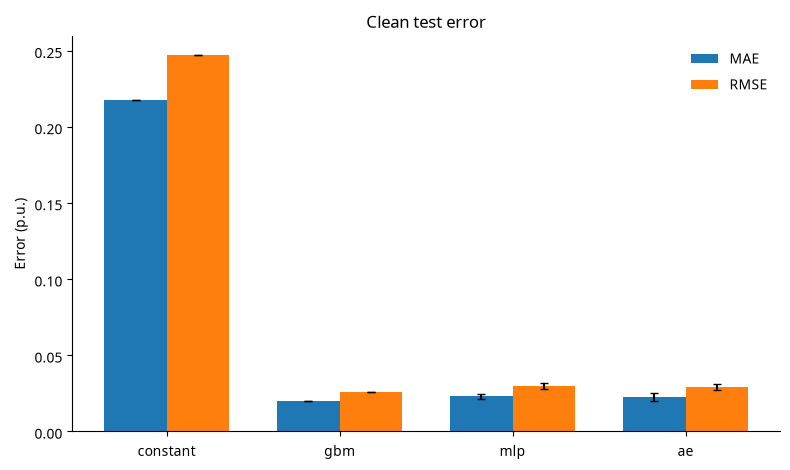

In [13]:
plot_data = comparison.set_index("model").loc[["constant", "gbm", "mlp", "ae"]]
x = np.arange(len(plot_data))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(x - width / 2, plot_data["MAE_mean"], width, yerr=plot_data["MAE_std"].fillna(0), capsize=3, label="MAE")
ax.bar(x + width / 2, plot_data["RMSE_mean"], width, yerr=plot_data["RMSE_std"].fillna(0), capsize=3, label="RMSE")
ax.set_xticks(x, plot_data.index)
ax.set_ylabel("Error (p.u.)")
ax.set_title("Clean test error")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "clean_test_metrics.png", dpi=160)
plt.show()
plt.close(fig)


## From regression to anomaly detection

The forecasting comparison identifies the GBM as the strongest predictor of `plant_pu`.
The detector uses the GBM residual, rather than the prediction itself, to identify unusual plant output.


## Residual-based detector

Calibration uses clean validation rows. Residuals are centered and scaled separately by solar-elevation slice, then smoothed over four consecutive rows.
The threshold is the 99.5th percentile of the validation `score_sm4` distribution.


In [14]:
def predict_pu(df):
    return unscale_y(gbm.predict(scale_x(df)).astype(np.float64))

val_cal = clean["val"].copy().sort_index()
val_cal["yhat_pu"] = predict_pu(val_cal)
val_cal["resid"] = val_cal[TARGET] - val_cal["yhat_pu"]

inner_edges = np.quantile(val_cal["solar_elev_deg"], np.arange(1, 8) / 8)
val_cal["slice"] = np.searchsorted(inner_edges, val_cal["solar_elev_deg"], side="right")

med_s = {}
sig_s = {}
for slice_id in range(8):
    values = val_cal.loc[val_cal["slice"].eq(slice_id), "resid"].to_numpy()
    med_s[slice_id] = float(np.median(values))
    sig_s[slice_id] = float(1.4826 * np.median(np.abs(values - med_s[slice_id])))

val_cal["score_pt"] = np.abs(
    (val_cal["resid"] - val_cal["slice"].map(med_s))
    / val_cal["slice"].map(sig_s)
)
val_cal["score_sm4"] = val_cal["score_pt"].rolling(4, min_periods=1).mean()
calibrated_threshold_sm4 = float(val_cal["score_sm4"].quantile(0.995))
threshold_file = BASE_DIR / "model_artifacts" / "thresholds.json"
if threshold_file.exists():
    threshold_sm4 = float(json.loads(threshold_file.read_text())["threshold_sm4"])
else:
    threshold_sm4 = calibrated_threshold_sm4
val_cal["alarm"] = val_cal["score_sm4"] >= threshold_sm4

calibration_summary = pd.DataFrame([{
    "validation_rows": len(val_cal),
    "calibrated_threshold_sm4": calibrated_threshold_sm4,
    "production_threshold_sm4": threshold_sm4,
    "validation_alarm_rate_pct": 100 * val_cal["alarm"].mean(),
}])
calibration_summary


,validation_rows,calibrated_threshold_sm4,production_threshold_sm4,validation_alarm_rate_pct
0,12146,4.616464,4.616006,0.502223


## Test alarms

Test scoring is applied to all scoreable rows, including rows excluded from the clean modeling subset.
`clean == 0` is not treated as ground truth here; it mixes data-quality rules, operational events, and event margins.


In [15]:
test_scored = tables["test"].loc[tables["test"]["scoreable"].eq(1)].copy().sort_index()
test_scored["yhat_pu"] = predict_pu(test_scored)
test_scored["resid"] = test_scored[TARGET] - test_scored["yhat_pu"]
test_scored["slice"] = np.searchsorted(inner_edges, test_scored["solar_elev_deg"], side="right")
test_scored["score_pt"] = np.abs(
    (test_scored["resid"] - test_scored["slice"].map(med_s))
    / test_scored["slice"].map(sig_s)
)
test_scored["score_sm4"] = test_scored["score_pt"].rolling(4, min_periods=1).mean()
test_scored["alarm"] = test_scored["score_sm4"] >= threshold_sm4

alarm_summary = pd.DataFrame([{
    "test_scoreable_rows": len(test_scored),
    "alarm_rows": int(test_scored["alarm"].sum()),
    "alarm_rate_pct": 100 * test_scored["alarm"].mean(),
    "threshold_sm4": threshold_sm4,
}])
alarm_summary.to_csv(RESULTS_DIR / "anomaly_test_summary.csv", index=False)
test_scored[[TARGET, "yhat_pu", "resid", "slice", "score_pt", "score_sm4", "alarm"]].to_csv(
    RESULTS_DIR / "test_anomaly_scores.csv"
)
alarm_summary


,test_scoreable_rows,alarm_rows,alarm_rate_pct,threshold_sm4
0,12180,47,0.385878,4.616006


## Residual distribution

This separates the residual distribution for rows below the alarm threshold from rows flagged by the detector.
It is a diagnostic plot, not a precision/recall evaluation because there is no pure row-level anomaly label.


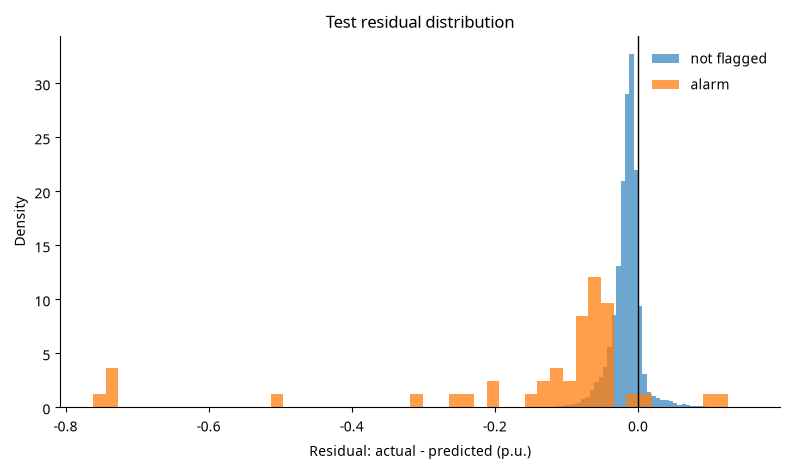

In [16]:
normal_resid = test_scored.loc[~test_scored["alarm"], "resid"]
alarm_resid = test_scored.loc[test_scored["alarm"], "resid"]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hist(normal_resid, bins=50, alpha=0.65, density=True, label="not flagged")
if len(alarm_resid):
    ax.hist(alarm_resid, bins=50, alpha=0.75, density=True, label="alarm")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Residual: actual - predicted (p.u.)")
ax.set_ylabel("Density")
ax.set_title("Test residual distribution")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "residual_distribution.png", dpi=160)
plt.show()
plt.close(fig)


## Alarm time series

The window is centered on the first test alarm when one is present; otherwise it shows the first scored test window.
Alarm points are overlaid on the observed and GBM-predicted plant output.


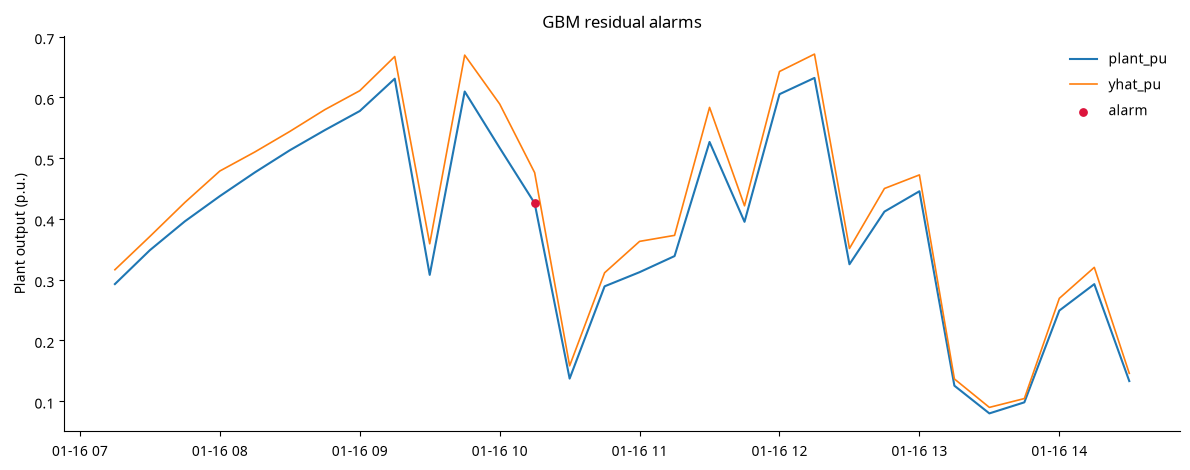

In [17]:
if len(alarm_resid):
    center = test_scored.index[test_scored["alarm"]][0]
    window = test_scored.loc[center - pd.Timedelta("12h"): center + pd.Timedelta("12h")]
else:
    window = test_scored.iloc[: min(192, len(test_scored))]

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(window.index, window[TARGET], label="plant_pu", linewidth=1.5)
ax.plot(window.index, window["yhat_pu"], label="yhat_pu", linewidth=1.2)
alarm_window = window.loc[window["alarm"]]
if len(alarm_window):
    ax.scatter(alarm_window.index, alarm_window[TARGET], color="crimson", s=28, label="alarm", zorder=3)
ax.set_ylabel("Plant output (p.u.)")
ax.set_title("GBM residual alarms")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "anomaly_timeseries.png", dpi=160)
plt.show()
plt.close(fig)


## Summary

The project has two stages: the GBM provides the plant-power estimate, and the residual detector turns unusual prediction errors into alarms.
GBM was selected by clean-test MAE/RMSE; `predict.py` is the operational version using the saved model, slice calibration, rolling score, and threshold.

The alarm rate and residual plots are descriptive. Precision, recall, and F1 are not reported because `clean == 0` is not a pure anomaly label.


In [18]:
best_test = comparison.sort_values(["RMSE_mean", "MAE_mean"]).iloc[0]
final_summary = pd.DataFrame([{
    "forecast_model": best_test["model"],
    "clean_test_mae": best_test["MAE_mean"],
    "clean_test_rmse": best_test["RMSE_mean"],
    "clean_test_r2": best_test["R2_mean"],
    "detector": "GBM residual + slice calibration + rolling score",
    "threshold_sm4": threshold_sm4,
    "test_scoreable_rows": len(test_scored),
    "test_alarm_rows": int(test_scored["alarm"].sum()),
    "test_alarm_rate_pct": 100 * test_scored["alarm"].mean(),
}])
final_summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
final_summary


,forecast_model,clean_test_mae,clean_test_rmse,clean_test_r2,detector,threshold_sm4,test_scoreable_rows,test_alarm_rows,test_alarm_rate_pct
0,gbm,0.020049,0.025917,0.988765,GBM residual + slice calibration + rolling score,4.616006,12180,47,0.385878
